# Supplementary Figure 3: Adoption signals

Compare cumulative Europe PMC mentions, GitHub stars, and 30-day PyPI downloads for the nine packages shown in the module. Each signal keeps its own units and logarithmic scale. Snapshot values were collected on 1 September 2026. See `MANUSCRIPT/02_SUPPLEMENTARY_INFO.md`, Supplementary Figures, Figure S3 caption, and Methods, Literature and repository data.


In [1]:
from pathlib import Path
import sys
from tempfile import TemporaryDirectory

import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import image as mpimg
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
REPO_ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'scripts' / 'census' / '_registry.py').is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate scripts/census/_registry.py from the notebook working directory')
SCRIPTS_DIR = REPO_ROOT / 'scripts'
FIGURES_DIR = SCRIPTS_DIR / 'census' / 'figures'
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.figures import sfig3_triangulation as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame

## Registry and query construction

The registry supplies the alias clauses and shared full-text microscopy context. The figure selects core packages with public repositories and available snapshot signals; its order is fixed in the module.


In [2]:
registry_table = pd.DataFrame([
    {'tool_id': tool.id, 'name': tool.name, 'category': tool.category, 'scope': tool.scope,
     'in_aggregate': tool.in_aggregate, 'aliases': ' | '.join(tool.aliases),
     'query': build_boolean_query(tool, reg.context_query)}
    for tool in reg.tools
])
print(f'{len(reg.tools)} packages; years {reg.year_start}-{reg.year_end}')
print(f'Shared context: {reg.context_query}')
print(f'Registry table shape: {registry_table.shape}')
display(registry_table.drop(columns='query').head(8))
display(registry_table.loc[registry_table.tool_id.isin(['imagej', 'napari', 'cellpose']), ['tool_id', 'aliases', 'query']])

30 packages; years 2010-2025
Shared context: (microscopy OR microscope) AND HAS_FT:Y
Registry table shape: (30, 7)


,tool_id,name,category,scope,in_aggregate,aliases
0,jupyter,Jupyter notebooks,notebook,core,False,Jupyter | Jupyter notebook | IPython notebook
1,imagej,ImageJ / Fiji,general-platform,core,True,ImageJ | ImageJ2 | Fiji | FIJI
2,napari,napari,general-platform,core,True,napari
3,cellprofiler,CellProfiler,general-platform,core,True,CellProfiler
4,qupath,QuPath,general-platform,core,True,QuPath
5,icy,Icy,general-platform,core,True,Icy bioimage | Icy software | de Chaumont Icy
6,ilastik,ilastik,general-platform,core,True,ilastik
7,knime,KNIME,general-platform,core,True,KNIME


,tool_id,aliases,query
1,imagej,ImageJ | ImageJ2 | Fiji | FIJI,"(""ImageJ2"" OR ""ImageJ"" OR ""Fiji"" OR ""FIJI"") AN..."
2,napari,napari,"""napari"" AND ((microscopy OR microscope) AND H..."
8,cellpose,Cellpose,"""Cellpose"" AND ((microscopy OR microscope) AND..."


In [3]:
lit = inspect_processed('literature_yearly.csv')
snapshot = inspect_processed('adoption_snapshot.csv')
inspect_processed('tools.csv')

literature_yearly.csv: shape=(960, 4)


,source,tool_id,year,count
0,openalex,jupyter,2010,0
1,openalex,jupyter,2011,0
2,openalex,jupyter,2012,0
3,openalex,jupyter,2013,0
4,openalex,jupyter,2014,0


adoption_snapshot.csv: shape=(15, 7)


,tool_id,category,github_stars,github_forks,earliest_repo,pypi_downloads_30d,imagesc_topics
0,jupyter,notebook,28733.0,9889.0,2015-04-09,99524642.0,0
1,imagej,general-platform,3221.0,875.0,2011-04-13,3885.0,0
2,napari,general-platform,2766.0,544.0,2018-08-13,146737.0,0
3,cellprofiler,general-platform,1137.0,425.0,2011-04-05,2225.0,0
4,qupath,general-platform,1455.0,361.0,2016-08-28,NaN,0


tools.csv: shape=(30, 7)


,tool_id,name,category,implies_dl,in_aggregate,scope,homepage
0,jupyter,Jupyter notebooks,notebook,False,False,core,https://jupyter.org
1,imagej,ImageJ / Fiji,general-platform,False,True,core,https://imagej.net
2,napari,napari,general-platform,False,True,core,https://napari.org
3,cellprofiler,CellProfiler,general-platform,False,True,core,https://cellprofiler.org
4,qupath,QuPath,general-platform,False,True,core,https://qupath.github.io


,tool_id,name,category,implies_dl,in_aggregate,scope,homepage
0,jupyter,Jupyter notebooks,notebook,False,False,core,https://jupyter.org
1,imagej,ImageJ / Fiji,general-platform,False,True,core,https://imagej.net
2,napari,napari,general-platform,False,True,core,https://napari.org
3,cellprofiler,CellProfiler,general-platform,False,True,core,https://cellprofiler.org
4,qupath,QuPath,general-platform,False,True,core,https://qupath.github.io
5,icy,Icy,general-platform,False,True,core,https://icy.bioimageanalysis.org
6,ilastik,ilastik,general-platform,False,True,core,https://www.ilastik.org
7,knime,KNIME,general-platform,False,True,core,https://www.knime.com
8,cellpose,Cellpose,dl-model,True,True,core,https://www.cellpose.org
9,stardist,StarDist,dl-model,True,True,core,https://github.com/stardist/stardist


## Three separate signals

For each displayed package, sum Europe PMC counts across 2010-2025 and join the 1 September 2026 GitHub-star and PyPI-download snapshots. Missing package values remain missing. The measures describe different activities and retain separate units.


In [4]:
tool_ids = figure.TOOLS
names = registry_table.set_index('tool_id')['name']
papers = fs.europepmc_yearly().groupby('tool_id')['count'].sum()
snapshot_indexed = snapshot.set_index('tool_id')
signals = pd.DataFrame(index=tool_ids)
signals['name'] = names.reindex(tool_ids)
signals['papers_2010_2025'] = papers.reindex(tool_ids)
signals['github_stars'] = pd.to_numeric(snapshot_indexed.github_stars.reindex(tool_ids), errors='coerce')
signals['pypi_downloads_30d'] = pd.to_numeric(snapshot_indexed.pypi_downloads_30d.reindex(tool_ids), errors='coerce')
print(f'Comparison table shape: {signals.shape}')
display(signals.reset_index(names='tool_id'))

for column in ['papers_2010_2025', 'github_stars', 'pypi_downloads_30d']:
    highest = signals[column].idxmax()
    print('{}: largest value is {:.0f} for {}.'.format(column, signals.loc[highest, column], signals.loc[highest].values[0]))

Comparison table shape: (9, 4)


,tool_id,name,papers_2010_2025,github_stars,pypi_downloads_30d
0,imagej,ImageJ / Fiji,362428,3221.0,3885.0
1,qupath,QuPath,4839,1455.0,NaN
2,cellprofiler,CellProfiler,6913,1137.0,2225.0
3,ilastik,ilastik,1876,408.0,NaN
4,napari,napari,657,2766.0,146737.0
5,cellpose,Cellpose,1666,2382.0,92270.0
6,stardist,StarDist,966,1272.0,27353.0
7,zerocostdl4mic,ZeroCostDL4Mic/DL4MicEverywhere,116,654.0,NaN
8,deepimagej,deepImageJ,62,99.0,NaN


papers_2010_2025: largest value is 362428 for ImageJ / Fiji.
github_stars: largest value is 3221 for ImageJ / Fiji.
pypi_downloads_30d: largest value is 146737 for napari.


## Optional processed-table rebuild from cached Europe PMC responses

Set `REBUILD = True` to reconstruct Europe PMC yearly counts and the microscopy denominator with the pipeline collection functions. A cache-only reader raises on missing responses, so this cell cannot fetch data. It writes comparison CSVs in a temporary folder and leaves `data/processed` unchanged. Repository-star and package-download snapshots remain the saved observations.


In [5]:
REBUILD = False
if REBUILD:
    import json
    from unittest.mock import patch
    from census import _http
    from census.sources import europepmc

    def cached_json(source, url, params=None, **kwargs):
        cache = _http._cache_path(source, url, params)
        if not cache.is_file():
            raise FileNotFoundError(f'Missing cached response: {cache.name}; no request was sent')
        return json.loads(cache.read_text())

    with patch.object(europepmc, 'get_json', cached_json):
        rebuilt_counts = pd.DataFrame(europepmc.collect_yearly(reg))
        rebuilt_corpus = pd.DataFrame(europepmc.corpus_yearly(reg))
    pd.testing.assert_frame_equal(rebuilt_counts.reset_index(drop=True), fs.europepmc_yearly().assign(source='europepmc')[rebuilt_counts.columns].reset_index(drop=True))
    pd.testing.assert_frame_equal(rebuilt_corpus, fs.load('corpus_yearly.csv'))
    with TemporaryDirectory(prefix='cached-processed-rebuild-') as output_dir:
        rebuilt_counts.to_csv(Path(output_dir) / 'literature_europepmc_yearly.csv', index=False)
        rebuilt_corpus.to_csv(Path(output_dir) / 'corpus_yearly.csv', index=False)
        print(f'Cached tables match: counts {rebuilt_counts.shape}, corpus {rebuilt_corpus.shape}')


## Render and compare

The final cell uses `style.save` for the notebook build, calls the module's `main(out_dir=...)` in a second temporary directory, compares the PNG arrays, and displays a scaled preview.


wrote SFigure3__triangulation.png/.pdf/.svg


wrote SFigure3__triangulation.png/.pdf/.svg
PNG shape: (932, 1913, 4); mean absolute pixel difference: 0.000000


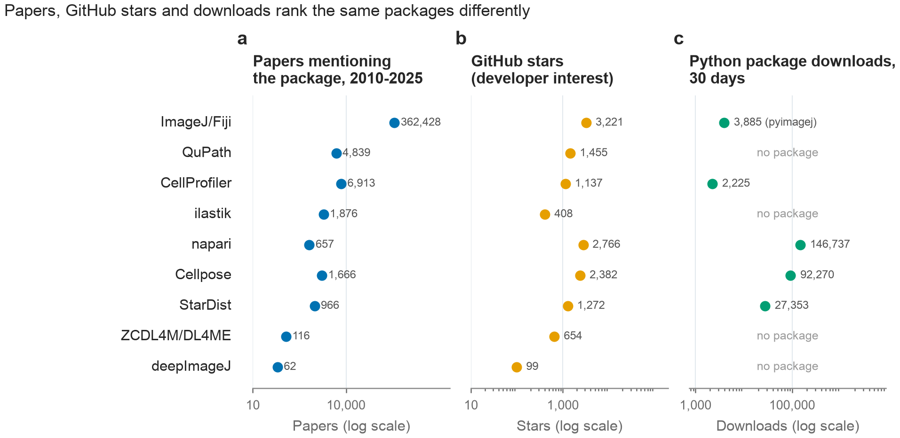

In [6]:
OUTPUT_STEM = 'SFigure3__triangulation'
fig = figure.build_figure()
with TemporaryDirectory(prefix='sfigure3-notebook-') as notebook_dir, TemporaryDirectory(prefix='sfigure3-module-') as module_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=notebook_dir)
    figure.main(out_dir=module_dir)
    notebook_png = Path(notebook_dir) / f'{OUTPUT_STEM}.png'
    module_png = Path(module_dir) / f'{OUTPUT_STEM}.png'
    notebook_image = mpimg.imread(notebook_png)
    module_image = mpimg.imread(module_png)
    assert notebook_image.shape == module_image.shape, (notebook_image.shape, module_image.shape)
    np.testing.assert_array_equal(notebook_image, module_image)
    print(f'PNG shape: {notebook_image.shape}; mean absolute pixel difference: {np.abs(notebook_image - module_image).mean():.6f}')
    from io import BytesIO
    from PIL import Image as PILImage
    preview = PILImage.open(notebook_png)
    preview.thumbnail((900, 900))
    preview_bytes = BytesIO()
    preview.save(preview_bytes, format='PNG')
    display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')